# 8장 · LLM 서비스 비교와 응답 평가

LLM 서비스를 비교하려면 같은 원문과 요청을 보내야 합니다. 답변의 각 주장을 원문에서 찾을 수 있는지가 이 실습의 비교 기준입니다.

‘참가비가 아직 정해지지 않았다’는 회의 메모가 요약본에서 ‘무료’로 바뀌었습니다. 같은 원문으로 만든 요약을 한 문장씩 대조한 뒤 비교 기록을 작성합니다. 노트북의 응답은 수업용 작성 예시입니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 원문에서 결정 사항과 미확정 안건 구분

서비스를 비교하려면 먼저 기준 원문이 필요합니다. 모임 일시, 장소, 담당자별 마감, 미정 사항을 같은 자료에서 확인한 뒤 어떤 응답을 받아도 같은 기준을 씁니다.


### ‘무료’라는 요약을 원문에서 확인하기

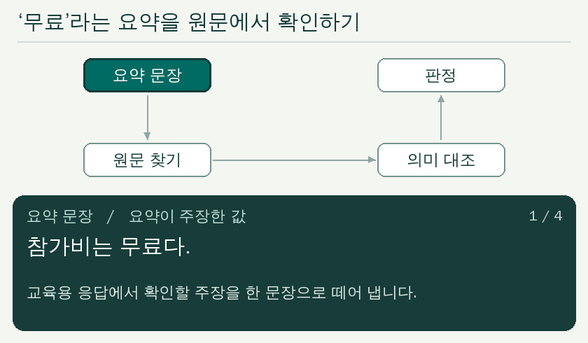

회의록과 요약에 ‘참가비’가 모두 있어도 두 문장이 같은 사실을 말하는지 따로 읽어야 합니다.


### 셀 01 · splitlines()로 원문 분리

아래 회의는 가상 사례입니다. 예산·참가비와 대면 모임에 관한 문장이 어느 쪽에 있는지 찾으세요.


In [1]:
meeting = """가상 독서 모임 운영 회의 / 2026-11-10
참석: 가상 인물 민수, 지연, 하늘
결정: 다음 모임은 11월 21일 토요일 14시, 온라인으로 진행한다.
지연은 11월 17일까지 참가 신청 양식을 만든다.
민수는 11월 18일까지 읽을 자료 후보 세 개를 공유한다.
하늘은 진행 순서를 정리한다. 마감일은 정하지 않았다.
예산과 참가비는 아직 합의하지 않았다.
검토 중: 대면 모임도 가능하지만 이번 회의에서 확정하지 않았다."""
print("\n".join(meeting.splitlines()[-2:]))

예산과 참가비는 아직 합의하지 않았다.
검토 중: 대면 모임도 가능하지만 이번 회의에서 확정하지 않았다.


예산과 참가비는 미합의, 대면 모임은 검토 단계입니다. 결정 사항에 적힌 이번 모임 방식은 온라인입니다.


### 셀 02 · 원문에서 요약의 근거 찾기

오프라인 대체 자료의 한 문장을 읽고 이를 뒷받침할 원문을 찾아보세요.


In [2]:
candidate = "참가비는 무료다."
evidence = next(line for line in meeting.splitlines() if "참가비" in line)
print(evidence)

예산과 참가비는 아직 합의하지 않았다.


‘예산과 참가비는 아직 합의하지 않았다.’가 나옵니다. 같은 단어가 있다고 해서 candidate를 지지하는 근거가 되지는 않습니다. 문장이 실제로 말하는 내용을 읽어야 합니다.


### 제공된 응답에서 근거 확인하기

<p>서비스에 접속할 수 없어도 ‘참가비는 무료다’라는 제공 문장을 회의록과 대조할 수 있습니다. ‘아직 합의하지 않았다’는 원문을 찾아 차이를 적고, 출처를 ‘제공 예시’로 표시하세요.</p>


## 동일 프롬프트를 사용한 응답 기록

ChatGPT·Claude·Gemini·Grok을 사용해 비교할 때는 같은 가상 원문과 요청을 새 대화에 넣습니다. 사용할 수 있는 서비스에서만 실습하고 실행 날짜, 화면에 표시된 모델, 파일 첨부 또는 본문 붙여넣기 여부를 적으세요. 모델명이 안 보이면 ‘미표시’로 남깁니다.


### 서비스·모델·대화

<p>서비스는 질문을 입력하는 화면을 제공하고, 모델은 입력을 바탕으로 답을 생성합니다. 같은 서비스라도 모델이나 이전 대화에 따라 답이 달라질 수 있습니다. 비교하려는 서비스마다 새 대화를 열고 같은 회의록을 넣어 보세요.</p>


### 셀 03 · 비교용 공통 프롬프트 조립

입력 방법을 바꾸어야 할 때도 원문과 요청 문장은 같게 유지하세요.


In [3]:
request = "결정 사항과 검토 중인 안건을 구분하고, 담당자와 마감을 원문대로 적어 주세요.\n\n" + meeting
print(request)

결정 사항과 검토 중인 안건을 구분하고, 담당자와 마감을 원문대로 적어 주세요.

가상 독서 모임 운영 회의 / 2026-11-10
참석: 가상 인물 민수, 지연, 하늘
결정: 다음 모임은 11월 21일 토요일 14시, 온라인으로 진행한다.
지연은 11월 17일까지 참가 신청 양식을 만든다.
민수는 11월 18일까지 읽을 자료 후보 세 개를 공유한다.
하늘은 진행 순서를 정리한다. 마감일은 정하지 않았다.
예산과 참가비는 아직 합의하지 않았다.
검토 중: 대면 모임도 가능하지만 이번 회의에서 확정하지 않았다.


첫 줄부터 회의록 마지막 줄까지 함께 복사하세요. 지시만 보내면 서비스가 날짜와 담당자를 확인할 원문이 없습니다.


### 비교할 입력과 기준 고정하기

<p>request에는 요청 문장과 회의록 전문이 함께 들어 있습니다. 각 서비스에 같은 내용을 보내고, 결정 사항·담당자·마감일이 원문과 맞는지 항목별로 기록하세요.</p>


### 과제 04 · 주장과 근거의 불일치 기록

대체 응답 B의 ‘하늘은 19일까지’라는 주장을 원문과 대조하고 고친 문장을 기록하세요. 서비스 실행 칸에는 넣지 않습니다.


In [4]:
claim = "하늘은 19일까지 진행 순서를 완성한다."
# claim의 마감일을 확인해 기록하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>claim = &quot;하늘은 19일까지 진행 순서를 완성한다.&quot;
source = next(line for line in meeting.splitlines() if line.startswith(&quot;하늘은&quot;))
review = {&quot;자료&quot;: &quot;교육용 응답 B&quot;, &quot;근거&quot;: source, &quot;수정&quot;: &quot;하늘은 진행 순서를 정리한다. 마감일은 미정이다.&quot;}
print(review[&quot;수정&quot;])</code></pre>
<p>실행 결과</p><pre><code>하늘은 진행 순서를 정리한다. 마감일은 미정이다.</code></pre>
<p>원문에 없는 19일을 지우고 담당 업무는 남깁니다. 비교표에는 관찰한 오류와 원문 위치를 적어야 다른 사람도 판정을 확인할 수 있습니다.</p>
</details>


### 근거 오류와 재요청 결과

<p>보완 요청에는 무엇이 잘못되었는지와 어떤 원문을 확인해야 하는지를 적습니다. 더 잘해 달라는 말만 반복하면 수정 기준이 모호합니다. 최초 요청, 최초 응답, 보완 요청, 수정 응답을 한 묶음으로 보관하세요.</p>

<p>모델이 사과하거나 수정했다고 말해도 다시 원문과 비교해야 합니다. 잘못된 항목을 고치면서 다른 담당자의 작업을 누락할 수 있습니다. 수정된 항목만 보지 말고 네 가지 기준을 다시 확인하세요.</p>


### 과제 05 · 서비스별 응답과 실행일 기록

서비스마다 한 건씩 실행한 기록을 채우세요. 접속할 수 없으면 아래 가상 예시 한 건을 원문과 대조하는 활동으로 마칩니다.

서비스를 사용할 수 있으면 실행 날짜·서비스 이름·받은 답을 같은 기록에 적으세요. 계정이 없으면 셀 02의 제공 답을 쓰고 출처를 ‘제공 예시’로 남기세요. 제공 답은 서비스 성능 비교의 관찰 건수에서 제외합니다.


In [5]:
services = ["ChatGPT", "Claude", "Gemini", "Grok"]
records = {name: {"확인일": "", "모델": "", "입력 방식": "", "받은 문장": "", "근거 판정": ""} for name in services}
# 자신이 사용한 서비스 한 곳의 항목부터 채우세요.
# 예: records["ChatGPT"]["확인일"] = "실제로 실행한 날짜"

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>example_record = {&quot;서비스&quot;: &quot;교육용 예시 B&quot;, &quot;확인일&quot;: &quot;실측 없음&quot;, &quot;모델&quot;: &quot;해당 없음&quot;,
                  &quot;입력 방식&quot;: &quot;대체 자료 읽기&quot;, &quot;받은 문장&quot;: &quot;참가비는 무료다.&quot;,
                  &quot;근거 판정&quot;: &quot;원문은 미합의이므로 수정 필요&quot;}
print(example_record[&quot;서비스&quot;], example_record[&quot;근거 판정&quot;])</code></pre>
<p>실행 결과</p><pre><code>교육용 예시 B 원문은 미합의이므로 수정 필요</code></pre>
<p>예시 B의 판단 근거는 회의 마지막 두 줄에서 찾았습니다. 실제로 얻은 응답은 본인이 쓴 서비스 칸에만 담습니다. 미실행 서비스의 빈칸은 그대로 두고 무료 여부와 마감일을 각각 비교하세요.</p>
</details>


### 서비스 응답과 실행일 기록하기

<p>ChatGPT에서 실행했다면 기록표의 ChatGPT 칸에 사용일과 모델 표시, 받은 문장 한 줄을 옮기세요. ‘하늘’에게 마감일을 부여했다면 회의록에서 이를 뒷받침하는 문장을 찾을 수 있는지 확인하세요.</p>


### Claude 응답의 동일 조건 비교

<p>새 대화에 동일한 자료와 요청을 넣습니다. 첫 서비스에서 본 오류를 막기 위한 문장을 추가하면 비교 조건이 달라집니다. 공통 요청은 그대로 두고 보완 실험은 첫 결과를 저장한 뒤 따로 진행하세요.</p>

<p>응답의 표가 보기 좋다는 이유로 사실 확인을 생략하지 않습니다. 예를 들어 하늘의 마감일을 다른 담당자의 마감일과 같게 적었다면 문서가 자연스러워도 근거 없는 추가입니다. 누락과 추가를 구분해 기록하세요.</p>


### Gemini·Grok 응답 비교

<p>두 서비스도 각각 새 대화에서 시작합니다. 사용 가능한 파일 입력이나 텍스트 입력을 선택하고 실제 입력 방법을 기록합니다. 첨부가 막히면 파일 종류·계정 안내·오류 메시지를 확인하고, 해결되지 않으면 대체 입력으로 진행하거나 미실행으로 남깁니다.</p>

<p>검색 기능이 자동으로 사용되었다면 외부 검색 결과와 첨부한 회의록의 내용을 섞었는지 확인합니다. 이번 과제의 근거는 회의록입니다. 외부 검색에서 찾은 행사를 이 모임의 결정 사항으로 넣어서는 안 됩니다.</p>

<p>계정이나 사용 한도 때문에 실행하지 못한 서비스를 다른 사람이 쓴 것처럼 기록하지 않습니다. 동료의 응답을 참고했다면 누가 실행한 결과인지와 조건을 표시합니다. 참고 결과는 본인의 직접 실행과 나누어 비교하세요.</p>

<table><caption>실행이 막히면</caption><thead><tr><th scope="col">상황</th><th scope="col">확인</th><th scope="col">대체</th></tr>
</thead><tbody><tr><td>파일 입력 불가</td><td>지원 파일·계정 조건</td><td>가상 텍스트 붙여넣기, 방법 기록</td></tr>
<tr><td>사용 한도 도달</td><td>화면의 한도 안내</td><td>다른 실행 가능 서비스 또는 교사 제공 응답 분석</td></tr>
<tr><td>모델 이름 미표시</td><td>선택 화면 존재 여부</td><td>미표시로 기록</td></tr>
<tr><td>원문과 다른 답변</td><td>해당 사실의 근거 문장</td><td>오류 표시 후 보완 요청</td></tr>
</tbody></table>


## 원문 일치도를 기준으로 서비스 비교

실제로 얻은 응답이 있다면 ‘정보를 지켰는가’, ‘어디를 수정해야 했는가’, ‘계정에서 어떤 입력을 할 수 있었는가’를 따로 적습니다. 아직 계정을 쓸 수 없는 경우에는 위의 교육용 응답 B를 원문에 맞게 고쳐 쓰면 됩니다.


### 서비스별 평가표

<p>이번 비교는 이 자료와 이 계정 조건에서 관찰한 결과입니다. 한 번의 회의록 요약으로 서비스 전체의 지능이나 안전성을 순위 매기지 않습니다. 먼저 기준별 통과 여부를 적고, 본인의 업무에 중요한 조건을 선택 이유로 설명하세요.</p>

<p>결정 사항이 맞는지, 할 일이 빠짐없이 나왔는지, 없는 정보를 미정으로 남겼는지, 제시한 근거가 원문에 있는지를 각각 판단합니다. 하나의 총점만 남기면 어떤 부분이 문제였는지 알기 어렵습니다.</p>

<table><caption>비교표의 판단 기준</caption><thead><tr><th scope="col">열</th><th scope="col">통과 조건</th></tr>
</thead><tbody><tr><td>decision_ok</td><td>일정·방식이 원문과 일치하고 검토안을 결정으로 바꾸지 않음</td></tr>
<tr><td>tasks_ok</td><td>담당자 세 명의 작업을 빠짐없이 구분</td></tr>
<tr><td>unknown_preserved</td><td>없는 마감일·예산·참가비를 만들어 넣지 않음</td></tr>
<tr><td>evidence_ok</td><td>각 근거가 실제 원문 문장에 대응</td></tr>
</tbody></table>

<p>이 코드는 필수 조건 칸이 비었는지만 확인합니다. 답변의 정확성을 자동 채점하지 않습니다. 표의 내용과 원문 대조는 사람이 수행합니다.</p>


### 과제 06 · 확정 안건 필터링

응답 B는 대면 모임으로 적었습니다. 원문의 결정 사항에서 장소와 일시가 있는 줄을 골라 출력하세요.


In [6]:
# ‘결정:’으로 시작하는 문장을 고르세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>decision = next(line for line in meeting.splitlines() if line.startswith(&quot;결정:&quot;))
print(decision)</code></pre>
<p>실행 결과</p><pre><code>결정: 다음 모임은 11월 21일 토요일 14시, 온라인으로 진행한다.</code></pre>
<p>11월 21일 토요일 14시, 온라인이라는 두 조건이 함께 나옵니다. 미확정인 대면 제안을 현재 결정으로 옮기면 일정 정보를 정확하게 읽은 답도 수정해야 합니다. 네 서비스를 비교할 때는 각 서비스에 같은 요청 전문을 넣고 실제로 받은 문장을 한 줄씩 옮기세요. 접속하지 못한 서비스의 결과 칸에는 ‘미실행’이라고 적으세요.</p>
</details>


### 과업별 서비스 선택 기준

<p>다음 장에서는 같은 작업을 더 명확하게 요청하는 방법을 배웁니다. 오늘 저장한 최초 요청과 실패 사례를 그대로 가져오세요.</p>


## 돌아보기

원문을 가린 채 요약만 보면 ‘19일’처럼 구체적인 숫자가 더 그럴듯해 보입니다. 비교한 서비스명 옆에는 반드시 자신이 확인한 문장 하나를 붙이세요. 대체 자료로 연습했다면 실제 서비스 성능이나 순위를 기록할 근거는 없습니다.
